# 02-2　穿隧效應：穿過古典力學說「絕對過不去」的牆

**前置**：[00-2 觀看前須知](../00_basics/02_before_quantum.ipynb)、[02-1 波包](01_wavepacket.ipynb)

02-1 的粒子是**自由**的，沒有任何東西擋著它。這一課在它前面放一道**牆**（位能障礙），看看會發生什麼事：

1. 一個能量**不夠**翻過牆的粒子，有一部分會**直接穿過去**
2. 和解析公式比對穿透機率
3. 牆越厚，穿透機率**指數下降**
4. 能量**夠**翻過牆的粒子，竟然也會被**反彈**一部分
5. 把 $\hbar$ 調小，穿隧消失，回到牛頓力學
6. 真實世界：晶片漏電、Flash 記憶體、太陽為什麼會發光

## 這一課的新觀念：位能圖與古典禁區

**白話**（高中的能量守恆）：一顆球滾向一座小山丘。

- 球的總能量 $E$ = 動能 + 位能
- 爬上山丘時，位能 $V$ 增加，動能減少
- 如果 $E < V_{\text{山頂}}$，球爬到一半動能就變成 0，只能**滾回來**

把位能 $V(x)$ 畫成一條曲線，再畫一條水平線代表總能量 $E$：

- $E > V$ 的地方：球可以去（動能是正的）
- $E < V$ 的地方：**古典禁區**，動能會是負的，不可能

這一課用最簡單的牆：**方形障礙**，高度 $V_0$、厚度 $a$。

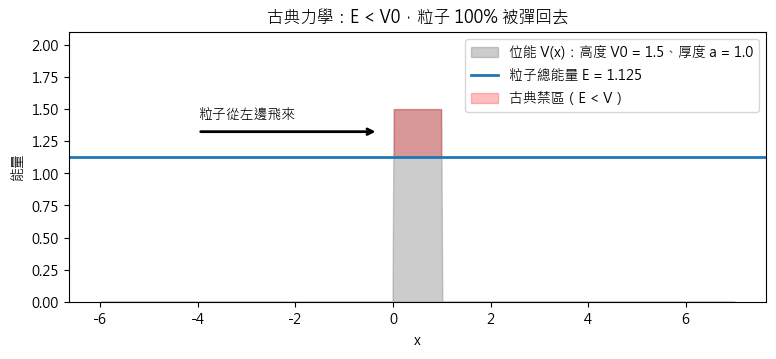

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

xs = np.linspace(-6, 7, 600)
V0, a, E = 1.5, 1.0, 1.125
Vx = np.where((xs >= 0) & (xs <= a), V0, 0.0)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.fill_between(xs, Vx, color="gray", alpha=0.4, label=f"位能 V(x)：高度 V0 = {V0}、厚度 a = {a}")
ax.axhline(E, color="C0", lw=2, label=f"粒子總能量 E = {E}")
ax.fill_between(xs, E, Vx, where=Vx > E, color="red", alpha=0.25, label="古典禁區（E < V）")
ax.annotate("", xy=(-0.3, E + 0.2), xytext=(-4, E + 0.2), arrowprops=dict(arrowstyle="->", lw=2))
ax.text(-4, E + 0.3, "粒子從左邊飛來")
ax.set_xlabel("x")
ax.set_ylabel("能量")
ax.set_ylim(0, 2.1)
ax.legend(loc="upper right")
ax.set_title("古典力學：E < V0，粒子 100% 被彈回去")
plt.show()

## 數值方法：split-step（分步法）

02-1 沒有位能，所以只要在**動量空間**轉相位。現在多了位能，薛丁格方程式變成

$$i\hbar\,\frac{\partial\psi}{\partial t} = \underbrace{-\frac{\hbar^2}{2m}\frac{\partial^2\psi}{\partial x^2}}_{\text{動能}} + \underbrace{V(x)\,\psi}_{\text{位能}}$$

兩項各自都很好處理：

- **位能那一項**：在**位置空間**，每個點的相位轉 $V(x)\,dt/\hbar$（位能越高轉越快）
- **動能那一項**：在**動量空間**，每個波數轉 $\hbar k^2\,dt/2m$（就是 02-1 的方法）

**分步法**就是把時間切成很小的 $dt$，兩種旋轉**輪流做**：位能半步 → 動能一步 → 位能半步。
和 00-1 的「一小步一小步」是同一個精神。

而且每一步都只是**轉相位**（乘上大小為 1 的 $e^{i\theta}$），所以**總機率自動守恆**。

In [2]:
hbar, m = 1.0, 1.0

def make_grid(L=409.6, N=4096):
    # 格距剛好 0.1，讓厚度 1 的牆剛好是 10 個格點
    x = np.linspace(-L / 2, L / 2, N, endpoint=False)
    dx = x[1] - x[0]
    k = 2 * np.pi * np.fft.fftfreq(N, d=dx)
    return x, dx, k


def gaussian(x, x0, sigma0, p0, hbar=1.0):
    return (2 * np.pi * sigma0**2) ** -0.25 * np.exp(
        -((x - x0) ** 2) / (4 * sigma0**2) + 1j * p0 * x / hbar
    )


def barrier(x, V0, a):
    return np.where((x >= 0) & (x < a), V0, 0.0)   # 半開區間 [0, a)：格點數 × 格距 = a


def split_step(psi, V, k, dt, steps, hbar=1.0, m=1.0):
    half_V = np.exp(-1j * V * dt / (2 * hbar))          # 位能半步：位置空間轉相位
    kinetic = np.exp(-1j * hbar * k**2 * dt / (2 * m))  # 動能一步：動量空間轉相位
    for _ in range(steps):
        psi = half_V * psi
        psi = np.fft.ifft(kinetic * np.fft.fft(psi))
        psi = half_V * psi
    return psi


def transmitted(psi, x, dx, a):
    # 牆右邊的總機率 = 穿透機率
    return np.sum(np.abs(psi[x > a]) ** 2) * dx

## 實驗 1：撞牆

粒子平均能量 $E = p_0^2/2m = 1.125$，牆高 $V_0 = 1.5$。古典答案：**全部彈回**。

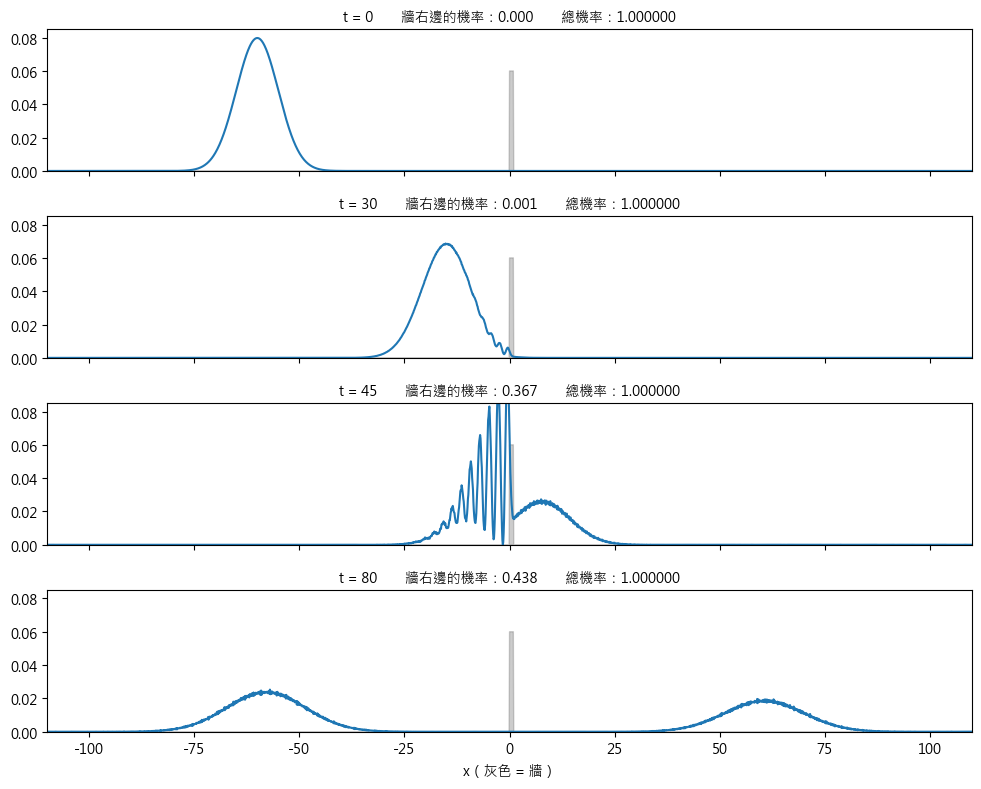

撞完之後：穿透 43.8%，反彈 56.2%（古典預測：穿透 0%）


In [3]:
x, dx, k = make_grid()
x0, sigma0, p0 = -60.0, 5.0, 1.5
V0, a = 1.5, 1.0
V = barrier(x, V0, a)
psi = gaussian(x, x0, sigma0, p0)
dt = 0.05

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
t = 0
for ax, t_target in zip(axes, [0, 30, 45, 80]):
    psi = split_step(psi, V, k, dt, int(round((t_target - t) / dt)))
    t = t_target
    ax.fill_between(x, V / V0 * 0.06, color="gray", alpha=0.4)
    ax.plot(x, np.abs(psi) ** 2, "C0")
    T_now = transmitted(psi, x, dx, a)
    ax.set_title(f"t = {t}　　牆右邊的機率：{T_now:.3f}　　總機率：{np.sum(np.abs(psi) ** 2) * dx:.6f}", fontsize=10)
    ax.set_ylim(0, 0.085)
axes[-1].set_xlim(-110, 110)
axes[-1].set_xlabel("x（灰色 = 牆）")
plt.tight_layout()
plt.show()

T_sim = transmitted(psi, x, dx, a)
print(f"撞完之後：穿透 {T_sim:.1%}，反彈 {1 - T_sim:.1%}（古典預測：穿透 0%）")

**觀察**：

- 波包撞到牆後**分成兩團**：大部分彈回左邊，但有一團**出現在牆的右邊**，繼續往前走。
- 總機率一直是 1，粒子沒有變多或變少，只是「在左邊」和「在右邊」的機率分開了。
- $t = 45$ 時，牆的左邊出現一條條**干涉條紋**：那是正要撞牆的波和剛被反彈的波疊在一起（00-2 第 1 章的疊加）。
- 這不是粒子「分成兩半」。如果在右邊放一個偵測器，每次偵測到的都是**一整顆**粒子，只是平均下來有一定比例的次數會偵測到。

**粒子怎麼能出現在古典禁區？** 波函數在牆裡面不會突然變成 0，而是**指數衰減**。
牆夠薄的話，衰減到牆的另一邊還剩一點點，那一點點就變成穿透過去的波。

## 實驗 2：和解析公式比對

對一個**能量確定**的波打在方形障礙上，穿透機率有精確的公式（$E < V_0$ 時）：

$$T(E) = \left[1 + \frac{V_0^2\,\sinh^2(\kappa a)}{4E(V_0 - E)}\right]^{-1},\qquad \kappa = \frac{\sqrt{2m(V_0 - E)}}{\hbar}$$

（$\sinh$ 是「雙曲正弦」，可以想成一個增長很快的函數，$x$ 大的時候約等於 $e^x/2$。）

$E > V_0$ 時把 $\sinh$ 換成 $\sin$，$\kappa$ 換成 $\sqrt{2m(E - V_0)}/\hbar$。

我們的波包不是單一能量，而是**一群波數**的組合（00-2 第 5 章），所以要把公式**對波包的動量分佈取平均**，再和模擬比。

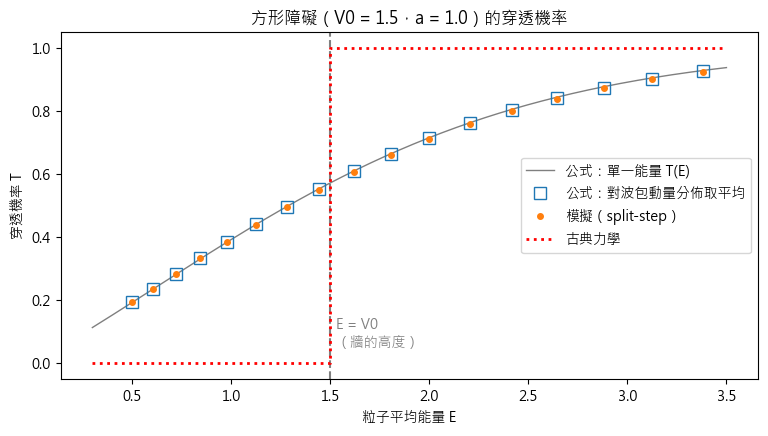

模擬和波包平均公式的最大差異：3.23e-03


In [4]:
def T_exact(E, V0, a, hbar=1.0, m=1.0):
    # 方形障礙的穿透機率；E < V0 和 E > V0 用同一條式子（複數開根號自動切換 sinh / sin）
    E = np.asarray(E, dtype=float)
    q = np.emath.sqrt(2 * m * (V0 - E)) / hbar
    s2 = np.abs(np.sinh(q * a)) ** 2
    return 1 / (1 + V0**2 * s2 / (4 * E * np.abs(V0 - E)))


def T_packet_average(psi0, k, V0, a, hbar=1.0, m=1.0):
    # 用波包初始的動量分佈 |φ(k)|² 當權重，平均 T(E)
    w = np.abs(np.fft.fft(psi0)) ** 2
    w /= w.sum()
    keep = (k > 0) & (w > 1e-14)
    E = (hbar * k[keep]) ** 2 / (2 * m)
    return np.sum(w[keep] * T_exact(E, V0, a, hbar, m))


def simulate_T(V0, a, p0, sigma0=5.0, x0=-60.0, dt=0.05):
    x, dx, k = make_grid()
    psi0 = gaussian(x, x0, sigma0, p0)
    t_end = 2 * abs(x0) / p0 + 10          # 足夠讓波包撞完並分開
    psi = split_step(psi0, barrier(x, V0, a), k, dt, int(t_end / dt))
    return transmitted(psi, x, dx, a), T_packet_average(psi0, k, V0, a)


p0s = np.linspace(1.0, 2.6, 17)
res = np.array([simulate_T(V0, a, p) for p in p0s])
E_mean = p0s**2 / 2

E_line = np.linspace(0.3, 3.5, 400)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(E_line, T_exact(E_line, V0, a), "k-", lw=1, alpha=0.5, label="公式：單一能量 T(E)")
ax.plot(E_mean, res[:, 1], "s", mfc="none", ms=9, label="公式：對波包動量分佈取平均")
ax.plot(E_mean, res[:, 0], "o", ms=4, label="模擬（split-step）")
ax.axvline(V0, color="gray", ls="--")
ax.text(V0 + 0.03, 0.05, "E = V0\n（牆的高度）", color="gray")
ax.plot([0.3, V0, V0, 3.5], [0, 0, 1, 1], "r:", lw=2, label="古典力學")
ax.set_xlabel("粒子平均能量 E")
ax.set_ylabel("穿透機率 T")
ax.set_title(f"方形障礙（V0 = {V0}，a = {a}）的穿透機率")
ax.legend(loc="center right")
plt.show()

print(f"模擬和波包平均公式的最大差異：{np.max(np.abs(res[:, 0] - res[:, 1])):.2e}")

**觀察**：

- 模擬的圓點**落在**方框（公式平均）裡，兩種完全不同的方法得到一樣的答案，差異只有千分之幾。
  （剩下的差異來自分步法的時間步長 $dt$，把 `dt` 改成 0.01 還會再小幾倍。）
- **紅色虛線是古典力學**：能量不夠就 0%，夠就 100%，是一個硬邦邦的階梯。
- 量子力學是一條**平滑的曲線**：
  - $E < V_0$ 時也有機會穿過去（**穿隧**）
  - $E > V_0$ 時**也不是 100%**，有一部分會被反彈（實驗 4 會看得更清楚）

## 實驗 3：牆越厚，穿透越難（指數衰減）

固定能量，改變牆的厚度 $a$。牆夠厚時，公式可以近似成

$$T \approx 16\,\frac{E}{V_0}\left(1-\frac{E}{V_0}\right)e^{-2\kappa a}$$

也就是**厚度每增加一點，穿透機率就乘上一個固定的倍數**，這叫**指數衰減**。用對數刻度畫會是一條直線。

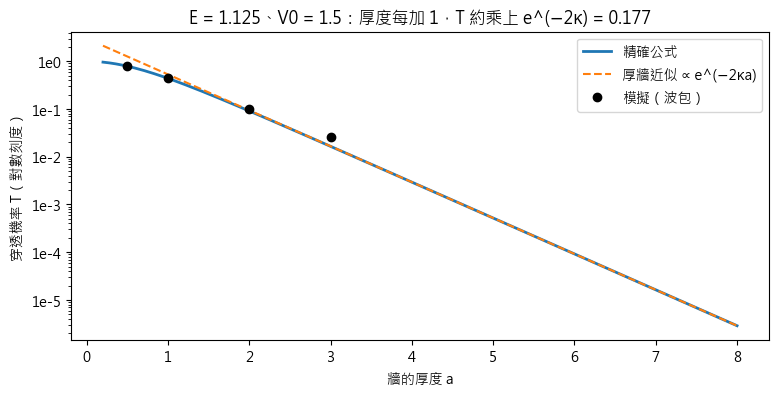

In [5]:
E0 = 1.125
kappa = np.sqrt(2 * m * (V0 - E0)) / hbar
widths = np.linspace(0.2, 8, 200)

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(widths, T_exact(E0, V0, widths), lw=2, label="精確公式")
ax.semilogy(widths, 16 * E0 / V0 * (1 - E0 / V0) * np.exp(-2 * kappa * widths), "--", label="厚牆近似 ∝ e^(−2κa)")
for a_sim in [0.5, 1.0, 2.0, 3.0]:
    T_sim, _ = simulate_T(V0, a_sim, np.sqrt(2 * E0))
    ax.semilogy(a_sim, T_sim, "ko")
ax.semilogy([], [], "ko", label="模擬（波包）")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"1e{np.log10(y):.0f}"))  # 避開數學字型缺負號
ax.set_xlabel("牆的厚度 a")
ax.set_ylabel("穿透機率 T（對數刻度）")
ax.set_title(f"E = {E0}、V0 = {V0}：厚度每加 1，T 約乘上 e^(−2κ) = {np.exp(-2 * kappa):.3f}")
ax.legend()
plt.show()

**觀察**：

- 牆夠厚之後，三者都變成**直線**，也就是指數衰減。
- 牆薄時模擬的點和公式吻合；牆越厚，模擬的點就**越高於**公式，厚度 3 時高了大約 4 倍。
  原因是波包不是單一能量：裡面能量比較高的成分穿透率高得多，牆越厚，穿過去的就幾乎都是這些「高能少數派」。
  這不是模擬錯了，而是**單一能量的公式不適用於有能量分佈的波包**。
- 「指數」的意思是：牆厚 2 倍，穿透機率不是變成 1/2，而是**平方**那樣地變小。所以穿隧在微觀世界很常見，到了日常尺度就完全消失。

## 實驗 4：能量夠，也會被反彈

$E > V_0$ 時，古典的球一定翻得過去。量子的波卻會在牆的邊緣**部分反射**，就像光照到玻璃，有一部分會被反射回來。

而且穿透率會**振盪**：牆的厚度剛好是牆內波長一半的整數倍時，兩個邊緣的反射互相抵消，穿透率變成 **100%**（共振穿透）。

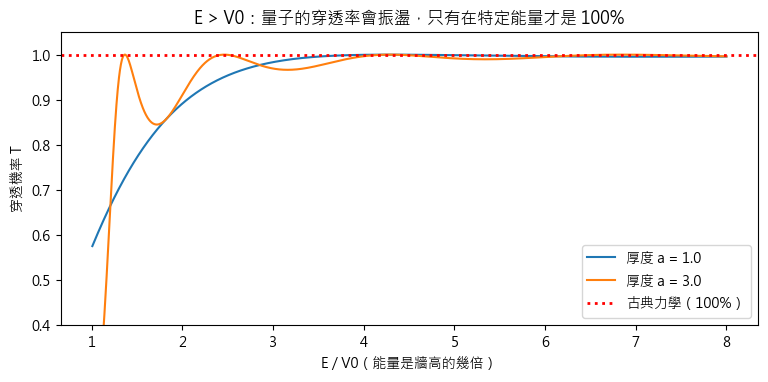

In [6]:
E_hi = np.linspace(V0 + 0.01, 8 * V0, 2000)
fig, ax = plt.subplots(figsize=(9, 3.8))
for a_show in [1.0, 3.0]:
    ax.plot(E_hi / V0, T_exact(E_hi, V0, a_show), label=f"厚度 a = {a_show}")
ax.axhline(1, color="r", ls=":", lw=2, label="古典力學（100%）")
ax.set_xlabel("E / V0（能量是牆高的幾倍）")
ax.set_ylabel("穿透機率 T")
ax.set_ylim(0.4, 1.05)
ax.set_title("E > V0：量子的穿透率會振盪，只有在特定能量才是 100%")
ax.legend(loc="lower right")
plt.show()

## 實驗 5：$\hbar \to 0$，穿隧消失

和 02-1 一樣，把 $\hbar$ 調小，看看會不會回到牛頓力學。
固定 $E/V_0 = 0.75$、$a = 1$，只改 $\hbar$：

In [7]:
print(f"{'ħ':>8}{'κa = a√(2m(V0−E))/ħ':>24}{'穿透機率 T':>16}")
for h in [1.0, 0.5, 0.2, 0.1, 0.05, 0.02]:
    ka = a * np.sqrt(2 * m * (V0 - E0)) / h
    print(f"{h:>8}{ka:>24.2f}{float(T_exact(E0, V0, a, hbar=h)):>16.3e}")

       ħ     κa = a√(2m(V0−E))/ħ          穿透機率 T
     1.0                    0.87       4.393e-01
     0.5                    1.73       9.097e-02
     0.2                    4.33       5.199e-04
     0.1                    8.66       9.014e-08
    0.05                   17.32       2.708e-15
    0.02                   43.30       7.347e-38


**觀察**：$\hbar$ 每變小一點，穿透機率就**指數地**掉下去。$\hbar$ 是 0.02 時已經是 $10^{-38}$ 等級。
$\hbar \to 0$ 時穿透機率趨近 0，回到牛頓力學的「絕對過不去」。

穿隧是一個**純粹的量子效應**，它的存在完全來自 $\hbar \ne 0$。

## 真實世界：穿隧無所不在

把公式換回真實單位：電子質量 $9.11\times10^{-31}$ kg，$\hbar = 1.055\times10^{-34}$ J·s，1 eV（電子伏特）$= 1.602\times10^{-19}$ J。

**例 1：晶片裡的氧化層漏電**。電晶體的閘極下面有一層很薄的絕緣層，用來擋住電子。
絕緣層的能障對電子來說約 3 eV。絕緣層越做越薄，電子穿隧過去的機率是：

In [8]:
hbar_SI, m_e, eV = 1.055e-34, 9.11e-31, 1.602e-19
barrier_eV = 3.0
kappa_SI = np.sqrt(2 * m_e * barrier_eV * eV) / hbar_SI

print(f"能障 {barrier_eV} eV → κ = {kappa_SI:.2e} /m")
print(f"{'絕緣層厚度':>10}{'穿透機率 ≈ e^(−2κa)':>24}")
for nm in [5, 3, 2, 1.5, 1.2, 1.0]:
    print(f"{nm:>8} nm{np.exp(-2 * kappa_SI * nm * 1e-9):>24.1e}")
print(f"\n厚度每少 0.1 nm，漏電大約變成 {np.exp(2 * kappa_SI * 0.1e-9):.1f} 倍")

能障 3.0 eV → κ = 8.87e+09 /m
     絕緣層厚度         穿透機率 ≈ e^(−2κa)
       5 nm                 3.0e-39
       3 nm                 7.7e-24
       2 nm                 3.9e-16
     1.5 nm                 2.8e-12
     1.2 nm                 5.7e-10
     1.0 nm                 2.0e-08

厚度每少 0.1 nm，漏電大約變成 5.9 倍


從 5 nm 減到 1 nm，穿透機率增加了**超過 $10^{30}$ 倍**。
這就是為什麼晶片製程縮到大約 1.2 nm 的二氧化矽層時，漏電大到無法接受，業界在 2007 年前後改用**高介電常數材料（high-k）**，讓絕緣層可以做厚一點、又維持同樣的電容。

**例 2：Flash 記憶體（SSD、隨身碟）**。資料存在一個被絕緣層完全包住的「浮動閘極」裡。
寫入和抹除時加上高電壓，讓能障變斜、變薄，電子就**穿隧**進出（Fowler–Nordheim 穿隧）；
平常沒有電壓時能障很厚，電子關在裡面可以存上十年。**你每存一個檔案，都在用穿隧效應。**

**例 3：太陽為什麼會發光**。太陽核心的兩個氫原子核都帶正電，互相排斥。
以核心約 1500 萬度的溫度，它們的能量**遠遠不夠**翻過這道排斥力的牆。如果沒有穿隧，核融合幾乎不會發生，太陽不會發光。

**例 4：掃描穿隧顯微鏡（STM）**。一根極尖的探針靠近表面，電子穿隧過去形成電流。
距離每改變 0.1 nm，電流就變化約 10 倍，靈敏到能**看見單一原子**（1986 年諾貝爾物理獎）。

## 動畫：穿隧

In [9]:
from matplotlib import animation
from IPython.display import HTML

x, dx, k = make_grid()
V = barrier(x, V0, a)
psi = gaussian(x, x0, sigma0, p0)
dt, steps_per_frame = 0.05, 40

fig, ax = plt.subplots(figsize=(8, 3), dpi=70)
ax.fill_between(x, V / V0 * 0.06, color="gray", alpha=0.4)
line, = ax.plot([], [], lw=2)
ax.set_xlim(-100, 100)
ax.set_ylim(0, 0.085)
ax.set_xlabel("x（灰色 = 牆）")
title = ax.set_title("")

def frame(i):
    global psi
    if i > 0:
        psi = split_step(psi, V, k, dt, steps_per_frame)
    line.set_data(x, np.abs(psi) ** 2)
    title.set_text(f"t = {i * steps_per_frame * dt:.0f}　　牆右邊的機率 = {transmitted(psi, x, dx, a):.3f}")
    return line, title

anim = animation.FuncAnimation(fig, frame, frames=45, interval=90, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## 總結

| 實驗 | 古典力學 | 量子力學 |
|---|---|---|
| $E < V_0$ 撞牆 | 100% 反彈 | 一部分**穿過去** |
| 穿透機率 | 0 或 1 的階梯 | 平滑曲線，模擬和公式吻合 |
| 牆變厚 | 沒差，反正過不去 | 穿透機率**指數下降** |
| $E > V_0$ | 100% 通過 | 會被**部分反彈**，穿透率振盪 |
| $\hbar \to 0$ | | 穿隧消失，回到古典 |

**和大問題的關係**：穿隧是 $\hbar \ne 0$ 最戲劇化的後果之一。到了 05 單元，霍金輻射有一種很直觀的理解方式，
就是把它看成**粒子從黑洞視界裡穿隧出來**（Parikh–Wilczek 圖像）。古典的黑洞是「什麼都出不來」的完美的牆，量子力學讓它不再完美。

## 練習

1. 實驗 1 把 `V0` 改成 3.0（牆更高），穿透機率變多少？把 `a` 改成 0.3（牆更薄）呢？
2. 把電子換成**質子**（質量是電子的 1836 倍），同樣 3 eV、1 nm 的能障，穿透機率是多少？為什麼穿隧主要是輕粒子的現象？
3. 實驗 4 的共振穿透：$a = 3$ 時，第一個 $T = 1$ 的能量在哪裡？用「牆內波長的一半剛好放得進牆」算算看：$k' a = \pi$，$k' = \sqrt{2m(E-V_0)}/\hbar$。